# Introduction to Machine Translation (MT):

Machine Translation is a subfield of AI and linguistics that develops systems capable of translating text from one language to another. The primary goal of machine translation is to enable effective communication between people who speak different languages by automating the process of language translation.

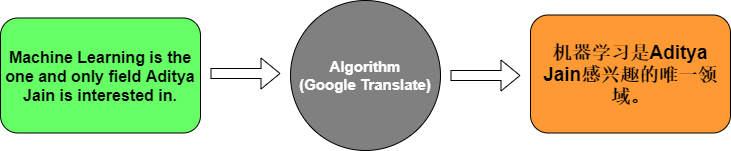

Challenges in Machine Translation:
- Ambiguity

Ex. I went to the bank.
- Idiomatic Expressions

Ex. It's raining cats and dogs.
- Low-Resource Languages

Some languages have very limited data.

Applications of Machine Translation:
- Global Business and E-commerce
-Cross-Cultural Communication
- Multilingual Content Creation
- Language Learning



## Neural Machine Translation:

Neural Machine Translation is a data-driven approach where a single large neural network learns to represent both the source language and the target language, and to directly map between them.
Instead of using manually defined rules or phrase tables, it learns translation patterns automatically from large datasets of bilingual text.

### Key Components of Neural Machine Translation:

<img src="https://drive.google.com/thumbnail?id=1xMmuMvOaYI73cYhQ1lbE5pIjDPWXhfgq&sz=w1000" width="600">


In [42]:
#!pip install tensorflow

In [46]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
import numpy as np

# Example bilingual dataset
english_sentences = ["Hello.", "How are you?", "This is a machine translation example."]
french_sentences = ["Bonjour.", "Comment ça va?", "Ceci est un exemple de traduction automatique."]

# Tokenize the english sentences
tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences) # Tokenize words and assign an integer ID to each unique word
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences) # Returns a list of tokens replaced by their index. Note: words index will start from 1 because 0 is reserved by default for padding (not assigned to any word).
print(f"eng_sequences = {eng_sequences}")
eng_word_index = tokenizer_eng.word_index # Returns the dictionary created by the tokenizer dict {word: index}.
print(f"eng_word_index = {eng_word_index}")

eng_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10]]
eng_word_index = {'hello': 1, 'how': 2, 'are': 3, 'you': 4, 'this': 5, 'is': 6, 'a': 7, 'machine': 8, 'translation': 9, 'example': 10}


In [47]:
# Tokenize the french sentences
tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)

print(f"frn_sequences = {frn_sequences}")
frn_word_index = tokenizer_frn.word_index
print(f"frn_word_index = {frn_word_index}")

frn_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10, 11]]
frn_word_index = {'bonjour': 1, 'comment': 2, 'ça': 3, 'va': 4, 'ceci': 5, 'est': 6, 'un': 7, 'exemple': 8, 'de': 9, 'traduction': 10, 'automatique': 11}


In [48]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Padding sequences
eng_padded = pad_sequences(eng_sequences) # makes all sequences the same length by padding with zeros at the beginning (default)
print(f"eng_padded = {eng_padded}")

eng_padded = [[ 0  0  0  0  0  1]
 [ 0  0  0  2  3  4]
 [ 5  6  7  8  9 10]]


In [49]:
frn_padded = pad_sequences(frn_sequences)
frn_padded

array([[ 0,  0,  0,  0,  0,  0,  1],
       [ 0,  0,  0,  0,  2,  3,  4],
       [ 5,  6,  7,  8,  9, 10, 11]], dtype=int32)

## LSTM Model

<img src="https://drive.google.com/uc?export=view&id=1rUaLO1wEOcUZ10Kwd0nUvS3jQzrqoOcI" width="550">

In [50]:
from sklearn.model_selection import train_test_split

# Train-test split
eng_train, eng_test, frn_train, frn_test = train_test_split(eng_padded, frn_padded, test_size=0.2, random_state=42)

# Define the model
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=len(eng_word_index) + 1, output_dim=64),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.RepeatVector(frn_padded.shape[1]), #length of french sentence
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(len(frn_word_index) + 1, activation='softmax')) #convert to probabilities for each frn word
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(eng_train, np.expand_dims(frn_train, -1), epochs=50, batch_size=1, validation_split=0.2)

# Evaluate the model
loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1))
print(f'Test Accuracy: {accuracy}')

Epoch 1/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - accuracy: 0.0000e+00 - loss: 2.4874 - val_accuracy: 0.0000e+00 - val_loss: 2.4871
Epoch 2/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - accuracy: 0.5714 - loss: 2.4786 - val_accuracy: 0.0000e+00 - val_loss: 2.4891
Epoch 3/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.5714 - loss: 2.4698 - val_accuracy: 0.0000e+00 - val_loss: 2.4911
Epoch 4/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.5714 - loss: 2.4607 - val_accuracy: 0.0000e+00 - val_loss: 2.4934
Epoch 5/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.5714 - loss: 2.4508 - val_accuracy: 0.0000e+00 - val_loss: 2.4958
Epoch 6/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - accuracy: 0.5714 - loss: 2.4399 - val_accuracy: 0.0000e+00 - val_loss: 2.4986
Epoch 7/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 0.5714 - loss: 2.4274 - val_accuracy: 0.0000e+00 - val_loss: 2.5018
Epoch 8/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.5714 - loss: 2.4129 - val_accura

In [51]:
# Inference
def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):
    sequence = eng_tokenizer.texts_to_sequences([sentence])
    padded_sequence = pad_sequences(sequence, maxlen=eng_padded.shape[1])
    predicted_sequence = model.predict(padded_sequence) #outputs probabilities for each timestep (french padded sentence) and each unique word in the target vocabulary.
    translated_sequence = np.argmax(predicted_sequence, axis=-1) #Returns the index (word ID) with the largest value at each timestep.
    translated_sentence = frn_tokenizer.sequences_to_texts(translated_sequence)
    return translated_sentence[0]

# Example Inference
input_sentence = "How are you?"
translated_sentence = translate_sentence(input_sentence, model, tokenizer_eng, tokenizer_frn)
print(f'Input: {input_sentence}\nTranslation: {translated_sentence}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 257ms/step
Input: How are you?
Translation: comment ça va


________________________________________________________________________________________________________________________________________

### Task 1: Understanding the Model Layers

Answer these simple questions in your own words:

1. What does the **Embedding** layer do to a word index?
3. What is the role of the **Encoder LSTM**?
5. What does the **Decoder LSTM** do?
8. Why do we use `softmax` in the final layer?


1. Changes word indexes into number vectors that the model can work with.

2. Reads the English sentence and understands its meaning.

3. Takes the information from the encoder and creates the French translation.

4. Gives probabilities for each word to select the most suitable French word.

### Task 2:

 Use Case: Language Translation (English-French)

A global e-commerce company wants to expand its reach to French-speaking customers and provide a seamless shopping experience. The company needs a language translation solution to automatically translate product listings, customer reviews, and other relevant content from English to French.

link: https://www.kaggle.com/datasets/devicharith/language-translation-englishfrench

In [52]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
import numpy as np
import pandas as pd

df = pd.read_csv("eng_-french.csv")
print(df.head())

english_sentences = df["English words/sentences"].dropna().tolist()[:1000]
french_sentences = df["French words/sentences"].dropna().tolist()[:1000]


  English words/sentences French words/sentences
0                     Hi.                 Salut!
1                    Run!                Cours !
2                    Run!               Courez !
3                    Who?                  Qui ?
4                    Wow!             Ça alors !


In [53]:
tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences)

eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences)
eng_word_index = tokenizer_eng.word_index

print("eng_sequences =", eng_sequences[:5])
print("eng_word_index =", eng_word_index)


eng_sequences = [[169], [75], [75], [60], [259]]
eng_word_index = {'i': 1, "i'm": 2, 'it': 3, 'go': 4, 'me': 5, 'tom': 6, "it's": 7, 'we': 8, 'up': 9, 'be': 10, 'you': 11, 'get': 12, 'this': 13, "i'll": 14, 'lost': 15, 'come': 16, 'take': 17, 'here': 18, 'on': 19, 'down': 20, 'saw': 21, 'stay': 22, 'won': 23, 'back': 24, 'they': 25, 'let': 26, 'try': 27, 'ok': 28, 'away': 29, 'out': 30, 'mine': 31, 'calm': 32, 'us': 33, 'is': 34, 'stop': 35, 'no': 36, 'nice': 37, 'see': 38, 'am': 39, 'a': 40, 'fun': 41, 'did': 42, 'over': 43, 'that': 44, 'help': 45, 'got': 46, 'in': 47, 'way': 48, 'fair': 49, 'keep': 50, 'still': 51, 'him': 52, 'call': 53, 'hold': 54, 'off': 55, 'grab': 56, 'how': 57, 'look': 58, 'must': 59, 'who': 60, 'wait': 61, 'left': 62, 'he': 63, 'ahead': 64, 'good': 65, 'job': 66, "he's": 67, 'use': 68, 'she': 69, 'watch': 70, "don't": 71, 'lie': 72, 'excuse': 73, 'forget': 74, 'run': 75, 'home': 76, 'talked': 77, 'sure': 78, 'leave': 79, 'what': 80, 'hot': 81, 'sorry': 82, 'fel

In [54]:

tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(french_sentences)

frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)
frn_word_index = tokenizer_frn.word_index

print("frn_sequences =", frn_sequences[:5])
print("frn_word_index =", frn_word_index)


frn_sequences = [[116], [317], [318], [36], [8, 319]]
frn_word_index = {'je': 1, 'suis': 2, 'nous': 3, 'tom': 4, 'moi': 5, "c'est": 6, 'est': 7, 'ça': 8, 'vous': 9, 'à': 10, "j'ai": 11, 'le': 12, 'il': 13, 'me': 14, 'toi': 15, 'en': 16, 'de': 17, 'la': 18, 'bien': 19, 'va': 20, 'pas': 21, 'aller': 22, 'soyez': 23, 'un': 24, 'a': 25, 'ici': 26, 'j’ai': 27, 'y': 28, 'avons': 29, 'laissez': 30, 'laisse': 31, 'ceci': 32, 'elle': 33, 'ce': 34, 'restez': 35, 'qui': 36, 'calme': 37, 'gagné': 38, 'perdu': 39, 'sois': 40, "j'en": 41, "m'en": 42, 'ai': 43, 'reste': 44, "l'ai": 45, 'vais': 46, 'tomber': 47, 'ne': 48, 'fait': 49, 'prends': 50, 'vu': 51, 'bon': 52, 'prenez': 53, 'les': 54, 'ils': 55, 'elles': 56, 'chez': 57, 'sommes': 58, 'au': 59, 'allez': 60, 'plus': 61, 'fais': 62, 'du': 63, 'regarde': 64, 'ont': 65, 'faut': 66, 'emporté': 67, 'maintenant': 68, 'demande': 69, 'pars': 70, 'aide': 71, 'signe': 72, 'garde': 73, 'trouve': 74, 'attrapez': 75, 'comme': 76, 'froid': 77, 'sûr': 78, 'ven

In [55]:
eng_padded = pad_sequences(eng_sequences)
frn_padded = pad_sequences(frn_sequences)

print("eng_padded =", eng_padded[:5])
print("frn_padded =", frn_padded[:5])


eng_padded = [[  0   0 169]
 [  0   0  75]
 [  0   0  75]
 [  0   0  60]
 [  0   0 259]]
frn_padded = [[  0   0   0   0   0   0 116]
 [  0   0   0   0   0   0 317]
 [  0   0   0   0   0   0 318]
 [  0   0   0   0   0   0  36]
 [  0   0   0   0   0   8 319]]


In [56]:

from sklearn.model_selection import train_test_split

eng_train, eng_test, frn_train, frn_test = train_test_split(
    eng_padded, frn_padded, test_size=0.2, random_state=42
)

model = tf.keras.Sequential([
    tf.keras.layers.Embedding(
        input_dim=len(eng_word_index) + 1, output_dim=64
    ),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.RepeatVector(frn_padded.shape[1]),
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.TimeDistributed(
        tf.keras.layers.Dense(
            len(frn_word_index) + 1, activation="softmax"
        )
    )
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.fit(
    eng_train,
    np.expand_dims(frn_train, -1),
    epochs=50,
    batch_size=1,
    validation_split=0.2
)

loss, accuracy = model.evaluate(
    eng_test, np.expand_dims(frn_test, -1)
)

print("Test Accuracy:", accuracy)


Epoch 1/50
640/640 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.6321 - loss: 2.9738 - val_accuracy: 0.6313 - val_loss: 2.5539
Epoch 2/50
640/640 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.6330 - loss: 2.2504 - val_accuracy: 0.6313 - val_loss: 2.5652
Epoch 3/50
640/640 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.6391 - loss: 2.1587 - val_accuracy: 0.6339 - val_loss: 2.5950
Epoch 4/50
640/640 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.6467 - loss: 2.0988 - val_accuracy: 0.6402 - val_loss: 2.6210
Epoch 5/50
640/640 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.6509 - loss: 2.0417 - val_accuracy: 0.6446 - val_loss: 2.6366
Epoch 6/50
640/640 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.6567 - loss: 1.9779 - val_accuracy: 0.6482 - val_loss: 2.6894
Epoch 7/50
640/640 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.6652 - loss: 1.9166 - val_accuracy: 0.6339 - val_loss: 2.6792
Epoch 8/50
640/640 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.6665 - loss: 1.8633 - val_accuracy: 0.

In [59]:
def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):
    sequence = eng_tokenizer.texts_to_sequences([sentence])
    padded_sequence = pad_sequences(
        sequence, maxlen=eng_padded.shape[1]
    )

    predicted_sequence = model.predict(padded_sequence)
    translated_sequence = np.argmax(predicted_sequence, axis=-1)
    translated_sentence = frn_tokenizer.sequences_to_texts(
        translated_sequence
    )

    return translated_sentence[0]

input_sentence = "Hi "

translated_sentence = translate_sentence(
    input_sentence, model, tokenizer_eng, tokenizer_frn
)

print("Input:", input_sentence)
print("Translation:", translated_sentence)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
Input: Hi 
Translation: salut
